# Extra analysis: do bookings with children cancel less?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv('../data/cleaned/hotel_bookings_cleaned.csv')
print(df.shape)
df.head()

(119389, 52)


,hotel,is_canceled,is_no_show,lead_time,lead_time_bucket,lead_time_bucket_order,arrival_date,arrival_date_year,arrival_month_num,arrival_date_month,...,adr_outlier,estimated_booking_value,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,zero_guests,zero_stay_nights,extreme_guest_count,is_duplicate_row
0,Resort Hotel,0,0,342,181-365 days,5,2015-07-01,2015,7,July,...,0,0.0,0,0,Check-Out,2015-07-01,0,1,0,0
1,Resort Hotel,0,0,737,365+ days,6,2015-07-01,2015,7,July,...,0,0.0,0,0,Check-Out,2015-07-01,0,1,0,0
2,Resort Hotel,0,0,7,0-7 days,1,2015-07-01,2015,7,July,...,0,75.0,0,0,Check-Out,2015-07-02,0,0,0,0
3,Resort Hotel,0,0,13,8-30 days,2,2015-07-01,2015,7,July,...,0,75.0,0,0,Check-Out,2015-07-02,0,0,0,0
4,Resort Hotel,0,0,14,8-30 days,2,2015-07-01,2015,7,July,...,0,196.0,0,1,Check-Out,2015-07-03,0,0,0,0


Question: Do bookings with children cancel less?
My guess: Yes, families plan ahead and are less likely to cancel.

In [2]:
df['children'].value_counts()

children
0     110799
1       4861
2       3652
3         76
10         1
Name: count, dtype: int64

In [3]:
df['has_children']=(df['children']>0).astype(int)
df['has_children'].value_counts()

has_children
0    110799
1      8590
Name: count, dtype: int64

In [4]:
df.groupby('has_children')['is_canceled'].agg(['size','mean'])

,size,mean
has_children,,
0,110799,0.370924
1,8590,0.363912


With all rows the cancellation rate is almost the same: 37.09% without children and 36.39% with children.

In [5]:
nd=df[df.is_duplicate_row==0]
nd.groupby('has_children')['is_canceled'].agg(['size','mean'])

,size,mean
has_children,,
0,79031,0.266225
1,8364,0.356887


In [6]:
print(df.groupby('has_children')['is_duplicate_row'].agg(['sum', 'mean']))

                sum      mean
has_children                 
0             31768  0.286717
1               226  0.026310


After removing duplicate rows the result changes: 26.62% without children and 35.69% with children. Almost all the duplicate rows (31,768 of 31,994) are bookings without children, so removing them changes the no-children rate a lot and the children rate very little.

In [7]:
all_rows = df.groupby('has_children')['is_canceled'].mean() * 100
no_dups = nd.groupby('has_children')['is_canceled'].mean() * 100
summary = pd.DataFrame({'all rows': all_rows, 'without duplicate rows': no_dups}).round(2)
summary.index = ['no children', 'with children']
summary

,all rows,without duplicate rows
no children,37.09,26.62
with children,36.39,35.69


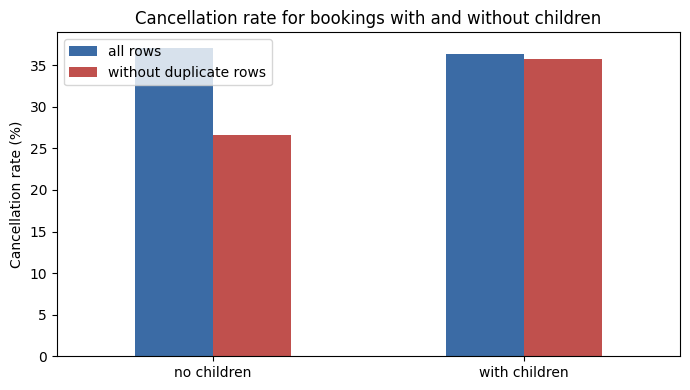

In [8]:
summary.plot(kind='bar', figsize=(7, 4), color=['#3B6BA5', '#C0504D'])
plt.ylabel('Cancellation rate (%)')
plt.title('Cancellation rate for bookings with and without children')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Conclusion

My guess was that bookings with children cancel less. The data doesn't support that.

With all rows the two groups are almost the same (37.09% vs 36.39%). Without the duplicate rows, bookings with children cancel more (35.69% vs 26.62%). The answer changes because almost all the duplicate rows are bookings without children.

The file has no booking ID, so I can't tell whether those rows are real duplicates. That means I can't say for sure that bookings with children cancel less, or more. I haven't looked into other factors, such as hotel, market segment or lead time.